# 03a · Anomaly detection with Spark MLlib (K-Means)
Unsupervised fraud/anomaly detection on session features. The dataset has no fraud labels, so a session is scored by its **distance to its nearest K-Means centroid**; the farthest 0.5% are flagged.

This notebook covers the Spark side on the **full 22.99M sessions**. `03b_anomaly_sklearn.ipynb` repeats the same algorithm without Spark on identical samples. Metrics go to `ml/outputs/03a_metrics.json`.

Open http://localhost:4040 while this runs (Spark UI screenshots for §5.4).

In [1]:
import os, json, time
import numpy as np, pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark import StorageLevel

DATA, OUT, FIG = "/home/jovyan/work/data", "/home/jovyan/work/ml/outputs", "/home/jovyan/work/laporan/gambar"
GOLD = f"{DATA}/gold"
SEED, MAXITER = 42, 20
metrics = {}

spark = (SparkSession.builder.master("local[*]").appName("03a_kmeans_mllib")
         .config("spark.driver.memory", "12g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

## 1. Feature preparation
16 features (hour, weekend and max_price are left out: they describe *when/what price*, not behaviour). Every feature is `log1p`-transformed because the counts and durations are extremely right-skewed (§4.1 / notebook 02), then standardised. Without the log, K-Means would spend its clusters on a handful of 4,000-event sessions.

In [2]:
FEATS = ["n_events","n_view","n_cart","n_purchase","n_products","n_categories","n_brands",
         "duration_sec","events_per_min","avg_gap_sec","cart_per_view","purchase_per_view",
         "purchase_per_cart","avg_price","purchase_value","purchase_no_view"]
sf = spark.read.parquet(f"{GOLD}/session_features")
sf_log = sf.select("user_session", "user_id", *[F.log1p(c).alias(c) for c in FEATS])

# shuffled, indexed 5M sub-sample shared with the scikit-learn notebook (identical rows on both sides)
from pyspark.sql import Window
t0 = time.time()
shuf = (sf_log.withColumn("r", F.rand(SEED)).orderBy("r").limit(5_000_000)
        .withColumn("rn", F.row_number().over(Window.orderBy("r"))).drop("r"))
shuf.write.mode("overwrite").parquet(f"{GOLD}/sf_log_5m")
print("shared sample written in", round(time.time()-t0), "s")

asm = VectorAssembler(inputCols=FEATS, outputCol="raw_vec")
scaler = StandardScaler(inputCol="raw_vec", outputCol="features", withMean=True, withStd=True)

def prep(df):
    v = asm.transform(df)
    return scaler.fit(v).transform(v)

full = prep(sf_log).select("user_session", "user_id", "features").persist(StorageLevel.MEMORY_AND_DISK)
N = full.count()
metrics["n_sessions"] = N
print(f"{N:,} sessions cached")

shared sample written in 33 s
22,995,676 sessions cached


## 2. Choosing k
WSSSE (elbow) and silhouette on a 500k sample for k = 2..10. Silhouette alone favours k=2 (one-event sessions vs the rest), which is not useful for finding odd behaviour, so the final k is the best silhouette among **k ≥ 4**.

In [3]:
sample = full.sample(False, 500_000 / N, seed=SEED).persist(StorageLevel.MEMORY_AND_DISK)
ev = ClusteringEvaluator(featuresCol="features", metricName="silhouette", distanceMeasure="squaredEuclidean")
rows = []
for k in range(2, 11):
    t0 = time.time()
    m = KMeans(k=k, seed=SEED, maxIter=MAXITER, featuresCol="features").fit(sample)
    pred = m.transform(sample)
    rows.append(dict(k=k, wssse=m.summary.trainingCost, silhouette=ev.evaluate(pred), fit_s=round(time.time()-t0, 1)))
    print(rows[-1])
ksel = pd.DataFrame(rows)
K = int(ksel[ksel.k >= 4].sort_values("silhouette", ascending=False).iloc[0].k)
metrics["k_selection"] = rows; metrics["k"] = K
print("chosen k =", K)

{'k': 2, 'wssse': 5773187.901012247, 'silhouette': 0.3673453829326167, 'fit_s': 6.1}
{'k': 3, 'wssse': 4943242.758777132, 'silhouette': 0.35156649200883633, 'fit_s': 2.5}
{'k': 4, 'wssse': 3408358.7643514876, 'silhouette': 0.5429560161137171, 'fit_s': 1.7}
{'k': 5, 'wssse': 2680984.2329778313, 'silhouette': 0.5541194423147204, 'fit_s': 2.1}
{'k': 6, 'wssse': 2297852.40482407, 'silhouette': 0.5953560141050254, 'fit_s': 1.7}
{'k': 7, 'wssse': 2103690.757566607, 'silhouette': 0.5459209173462195, 'fit_s': 1.8}
{'k': 8, 'wssse': 2398375.0258751293, 'silhouette': 0.49111188873061956, 'fit_s': 1.8}
{'k': 9, 'wssse': 1926348.8436440898, 'silhouette': 0.5080164891521192, 'fit_s': 1.9}
{'k': 10, 'wssse': 1829494.7830711454, 'silhouette': 0.5102169063822366, 'fit_s': 1.9}
chosen k = 6


{'k': 4, 'wssse': 3408358.7643514876, 'silhouette': 0.5429560161137171, 'fit_s': 1.5}


{'k': 5, 'wssse': 2680984.232977831, 'silhouette': 0.5541194423147204, 'fit_s': 1.8}


{'k': 6, 'wssse': 2297852.4048240706, 'silhouette': 0.5953560141050254, 'fit_s': 1.5}


{'k': 7, 'wssse': 2103690.7575666066, 'silhouette': 0.5459209173462195, 'fit_s': 1.8}


{'k': 8, 'wssse': 2398375.0258751293, 'silhouette': 0.49111188873061956, 'fit_s': 1.8}


{'k': 9, 'wssse': 1926348.8436440898, 'silhouette': 0.5080164891521192, 'fit_s': 1.8}


{'k': 10, 'wssse': 1829494.7830711452, 'silhouette': 0.5102169063822366, 'fit_s': 1.8}
chosen k = 6


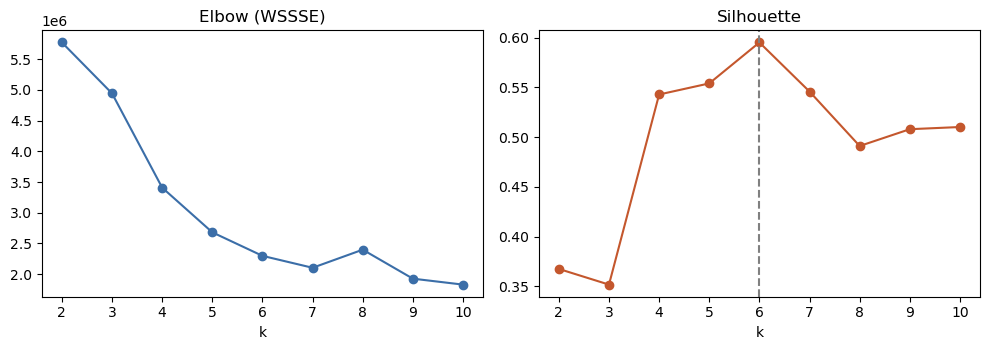

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(ksel.k, ksel.wssse, "o-", color="#3b6ea8"); ax[0].set_title("Elbow (WSSSE)"); ax[0].set_xlabel("k")
ax[1].plot(ksel.k, ksel.silhouette, "o-", color="#c4572d"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
ax[1].axvline(K, ls="--", color="gray")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_5_2_kmeans_k_selection.png", dpi=160); plt.show()

## 3. Scalability: same algorithm, growing data
Spark K-Means fit time (input already cached, so only the algorithm is timed) on the shared 100k to 5M samples plus the full dataset. `03b` times scikit-learn on the same rows.

In [5]:
shared = spark.read.parquet(f"{GOLD}/sf_log_5m")

def scaled_subset(n):
    d = shared.filter(F.col("rn") <= n)
    return prep(d).select("features").persist(StorageLevel.MEMORY_AND_DISK)

scal = []
for n in [100_000, 500_000, 1_000_000, 2_000_000, 5_000_000]:
    d = scaled_subset(n); d.count()
    t0 = time.time(); m = KMeans(k=K, seed=SEED, maxIter=MAXITER).fit(d); dt = time.time() - t0
    scal.append(dict(n=n, fit_s=round(dt, 1), wssse_per_row=m.summary.trainingCost / n, iters=m.summary.numIter))
    print(scal[-1]); d.unpersist()

t0 = time.time(); model = KMeans(k=K, seed=SEED, maxIter=MAXITER, featuresCol="features").fit(full); dt = time.time() - t0
scal.append(dict(n=N, fit_s=round(dt, 1), wssse_per_row=model.summary.trainingCost / N, iters=model.summary.numIter))
print(scal[-1])
metrics["scalability"] = scal

{'n': 100000, 'fit_s': 1.4, 'wssse_per_row': 5.195983015353894, 'iters': 20}
{'n': 500000, 'fit_s': 5.8, 'wssse_per_row': 5.2493301840461575, 'iters': 20}
{'n': 1000000, 'fit_s': 11.0, 'wssse_per_row': 4.916278958443785, 'iters': 20}
{'n': 2000000, 'fit_s': 20.8, 'wssse_per_row': 5.328248979974736, 'iters': 20}
{'n': 5000000, 'fit_s': 23.2, 'wssse_per_row': 5.616821231623809, 'iters': 20}
{'n': 22995676, 'fit_s': 67.3, 'wssse_per_row': 4.568460628449952, 'iters': 17}


{'n': 1000000, 'fit_s': 9.9, 'wssse_per_row': 4.916278958443785, 'iters': 20}


{'n': 2000000, 'fit_s': 19.8, 'wssse_per_row': 5.328248979974736, 'iters': 20}


{'n': 5000000, 'fit_s': 21.9, 'wssse_per_row': 5.616821231623809, 'iters': 20}


{'n': 22995676, 'fit_s': 50.3, 'wssse_per_row': 4.568460628449951, 'iters': 17}


## 4. Anomaly scores on all sessions
`score` = Euclidean distance (in standardised log space) to the assigned centroid. Threshold = 99.5th percentile.

In [6]:
centers = np.array(model.clusterCenters())
bc = spark.sparkContext.broadcast(centers)

@F.pandas_udf("double")
def dist_to_center(arr: pd.Series, pred: pd.Series) -> pd.Series:
    X = np.stack(arr.to_numpy()); c = bc.value[pred.to_numpy()]
    return pd.Series(np.sqrt(((X - c) ** 2).sum(axis=1)))

scored = (model.transform(full)
          .withColumn("score", dist_to_center(vector_to_array("features"), F.col("prediction")))
          .drop("features"))
scored.write.mode("overwrite").parquet(f"{GOLD}/session_scores")
sc = spark.read.parquet(f"{GOLD}/session_scores")
thr = sc.approxQuantile("score", [0.995], 0.0001)[0]
metrics["threshold_p995"] = thr
print("threshold", thr)

threshold 7.072270060669612


In [7]:
# cluster sizes and behaviour profile on the ORIGINAL (un-logged) features
# two ways to be flagged: far from the centroid (distance), or member of a tiny cluster (< 0.1% of sessions)
sizes = {r["prediction"]: r["count"] for r in sc.groupBy("prediction").count().collect()}
small = [c for c, n_ in sizes.items() if n_ / N < 0.001]
metrics["cluster_sizes"] = sizes; metrics["small_clusters"] = small
print("small clusters:", small, [sizes[c] for c in small])
prof = (sf.join(sc.select("user_session","prediction","score"), "user_session")
          .withColumn("flag_dist", (F.col("score") >= thr).cast("int"))
          .withColumn("flag_small", F.col("prediction").isin(small).cast("int"))
          .withColumn("flag", ((F.col("flag_dist") + F.col("flag_small")) > 0).cast("int"))
          .persist(StorageLevel.MEMORY_AND_DISK))
PROF = ["n_events","n_products","duration_sec","events_per_min","cart_per_view","purchase_per_view","purchase_no_view","avg_price"]
by_cluster = prof.groupBy("prediction").agg(F.count("*").alias("sessions"), *[F.avg(c).alias(c) for c in PROF]).orderBy("prediction").toPandas()
by_flag = prof.groupBy("flag_dist", "flag_small").agg(F.count("*").alias("sessions"), *[F.avg(c).alias(c) for c in PROF]).orderBy("flag_dist", "flag_small").toPandas()
metrics["by_cluster"] = by_cluster.to_dict(orient="records"); metrics["by_flag"] = by_flag.to_dict(orient="records")
display(by_cluster.round(3)); display(by_flag.round(3))

small clusters: [3] [7009]


,prediction,sessions,n_events,n_products,duration_sec,events_per_min,cart_per_view,purchase_per_view,purchase_no_view,avg_price
0,0,8585143,3.602,2.424,2104.707,2.510,0.000,0.000,0.0,328.157
1,1,8464480,1.026,1.004,0.160,59.149,0.000,0.000,0.0,318.268
2,2,1093958,5.970,2.105,544.190,5.003,0.600,0.001,0.0,318.786
3,3,7009,1.566,1.013,60.525,35.617,0.541,1.025,1.0,334.043
4,4,1377224,7.748,2.790,674.962,1.738,0.376,0.439,0.0,304.815
5,5,3467862,15.208,9.835,1645.161,1.321,0.007,0.000,0.0,263.101


,flag_dist,flag_small,sessions,n_events,n_products,duration_sec,events_per_min,cart_per_view,purchase_per_view,purchase_no_view,avg_price
0,0,0,22873026,4.618,2.958,1088.628,23.365,0.046,0.025,0.0,313.104
1,0,1,6777,1.451,1.008,48.857,36.781,0.435,1.016,1.0,334.855
2,1,0,115641,33.984,16.410,3462.615,1.993,1.177,0.276,0.0,264.101
3,1,1,232,4.909,1.142,401.353,1.614,3.616,1.293,1.0,310.323


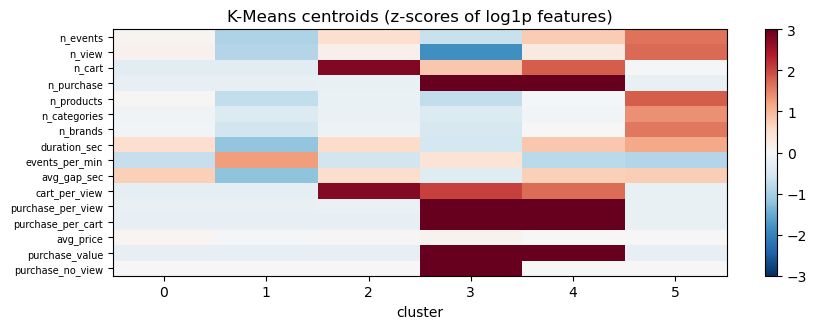

In [8]:
# centroid heat-map (standardised log space) for the report
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(centers.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS, fontsize=7)
ax.set_xticks(range(K)); ax.set_xlabel("cluster"); ax.set_title("K-Means centroids (z-scores of log1p features)")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig(f"{FIG}/fig_5_3_kmeans_centroids.png", dpi=160); plt.show()

## 5. Evaluation without labels
Three checks, none of which is an accuracy figure (there are no ground-truth fraud labels):

1. **Silhouette** from §2.
2. **Consistency with rules.** Two simple rules mirror the Assignment 1 rule layer: *bot-like* (≥ 20 events with average gap ≤ 2 s) and *purchase without any view*. We report the lift of each rule inside the flagged 0.5% versus its base rate, and the ROC-AUC of the score against the combined rule flag. This is partly circular (rule inputs are model features) so it is a sanity check on direction, not validation.
3. **Stability.** Adjusted Rand Index between two fits with different seeds on the same 500k sample.

In [9]:
rules = (prof
   .withColumn("r_bot", ((F.col("n_events") >= 20) & (F.col("avg_gap_sec") <= 2)).cast("int"))
   .withColumn("r_nov", F.col("purchase_no_view"))
   .withColumn("r_any", ((F.col("r_bot") + F.col("r_nov")) > 0).cast("int")))
tot = rules.agg(F.count("*").alias("n"), F.sum("flag").alias("flagged"), F.sum("flag_dist").alias("flagged_dist"), F.sum("flag_small").alias("flagged_small"), F.sum("r_bot").alias("bot"),
                F.sum("r_nov").alias("nov"), F.sum("r_any").alias("any")).first().asDict()
inflag = rules.filter("flag = 1").agg(F.avg("r_bot").alias("bot"), F.avg("r_nov").alias("nov"), F.avg("r_any").alias("any")).first().asDict()
lift = {k: inflag[k] / (tot[k] / tot["n"]) if tot[k] else None for k in ["bot", "nov", "any"]}  # combined flag
inflag_d = rules.filter("flag_dist = 1").agg(F.avg("r_bot").alias("bot"), F.avg("r_nov").alias("nov"), F.avg("r_any").alias("any")).first().asDict()
lift_d = {k: inflag_d[k] / (tot[k] / tot["n"]) if tot[k] else None for k in ["bot", "nov", "any"]}
metrics["rules"] = dict(totals=tot, share_in_flagged=inflag, lift=lift, share_in_flagged_distance_only=inflag_d, lift_distance_only=lift_d)
print("distance-only lift", lift_d)
print(tot); print(inflag); print("lift", lift)

# ROC-AUC of score vs combined rule flag, on a 1M sample
from sklearn.metrics import roc_auc_score
s = rules.sample(False, 1_000_000 / N, seed=SEED).select("score", "r_any").toPandas()
metrics["auc_vs_rules"] = float(roc_auc_score(s.r_any, s.score)); print("AUC vs rules", metrics["auc_vs_rules"])

distance-only lift {'bot': 141.75418654166938, 'nov': 6.5689484646503375, 'any': 6.703825412560705}
{'n': 22995676, 'flagged': 122650, 'flagged_dist': 115873, 'flagged_small': 7009, 'bot': 7, 'nov': 7009, 'any': 7016}
{'bot': 4.076640847941296e-05, 'nov': 0.057146351406441094, 'any': 0.05718711781492051}
lift {'bot': 133.92158872517618, 'nov': 187.49022421524663, 'any': 187.43677774312144}
AUC vs rules 0.9294749811616707


In [10]:
from sklearn.metrics import adjusted_rand_score
m2 = KMeans(k=K, seed=7, maxIter=MAXITER, featuresCol="features").fit(sample)
m1 = KMeans(k=K, seed=SEED, maxIter=MAXITER, featuresCol="features").fit(sample)
a = m1.transform(sample).select("prediction").toPandas().prediction
b = m2.transform(sample).select("prediction").toPandas().prediction
metrics["ari_seed_stability"] = float(adjusted_rand_score(a, b)); print("ARI", metrics["ari_seed_stability"])

ARI 0.9921637437662422


In [11]:
# suspicious users handed to the graph analysis (notebook 05)
flag_users = (rules.filter("flag = 1").groupBy("user_id")
              .agg(F.count("*").alias("flagged_sessions"), F.max("score").alias("max_score"))
              .orderBy(F.desc("flagged_sessions")))
flag_users.write.mode("overwrite").parquet(f"{GOLD}/suspicious_users")
metrics["suspicious_users"] = flag_users.count()
metrics["flagged_sessions"] = int(tot["flagged"])
json.dump(metrics, open(f"{OUT}/03a_metrics.json", "w"), indent=2, default=str)
print(metrics["suspicious_users"], "users with at least one flagged session")
spark.stop()

101532 users with at least one flagged session
